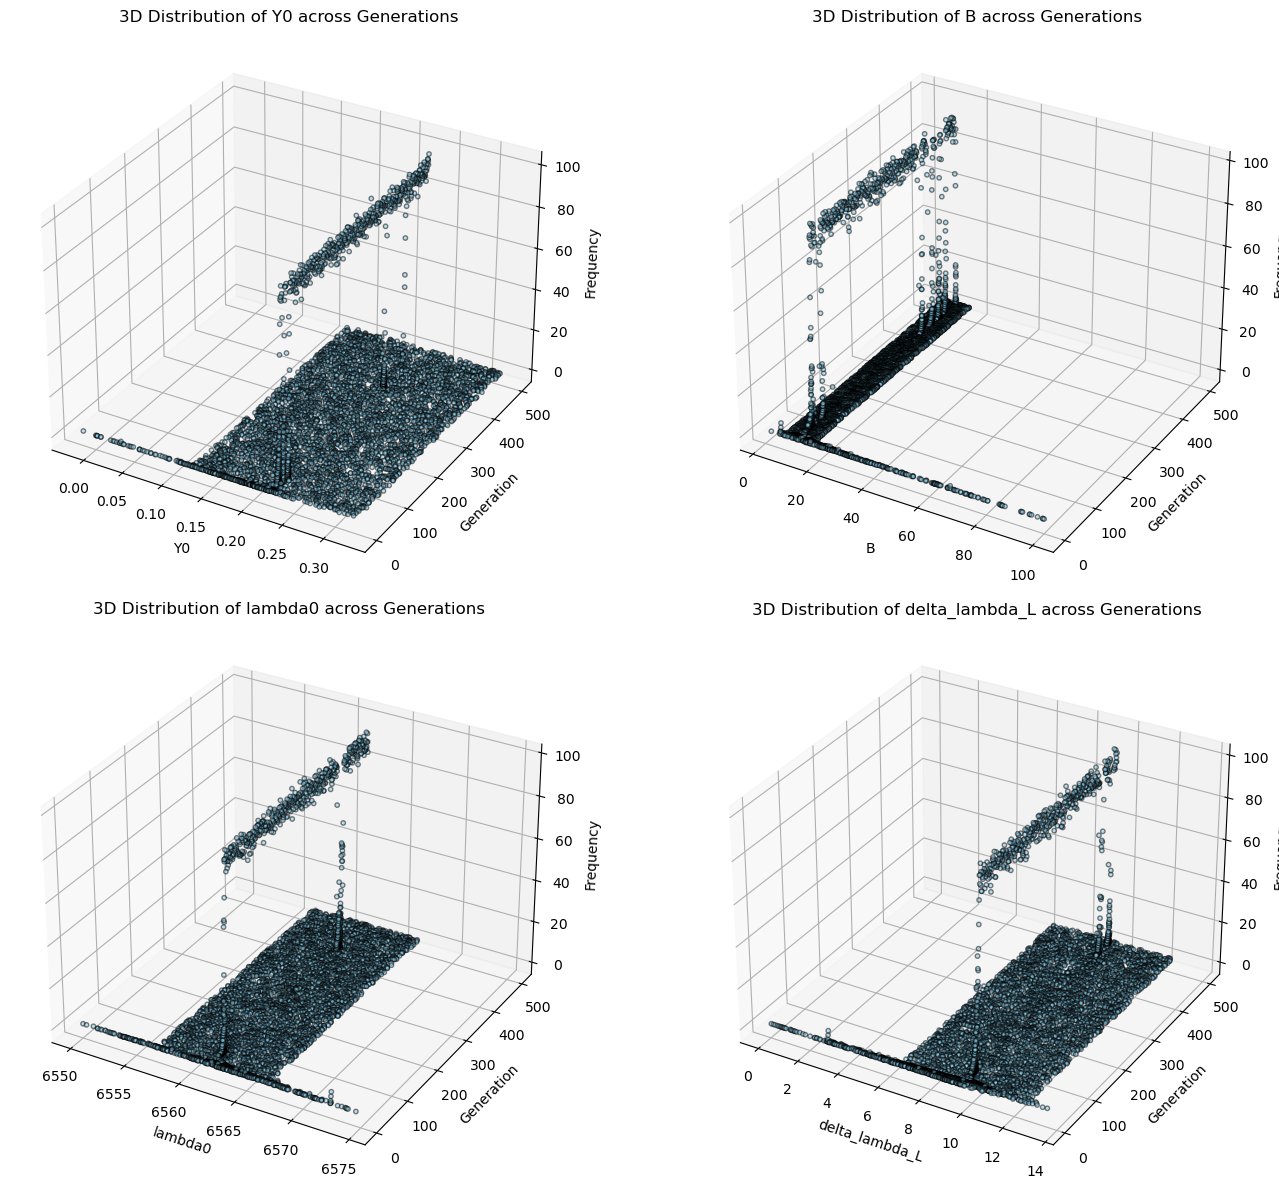

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D


# 读取CSV文件
df = pd.read_csv(r'C:\Users\QianBoda\Desktop\Project_Numerique\N2_C\N2_C\genetic_algorithm_data.csv')

# 创建一个图形窗口
fig = plt.figure(figsize=(15, 12))

# 参数列表
param_names = ["Y0", "B", "lambda0", "delta_lambda_L"]

# 迭代所有参数，绘制3D图
for i, param_name in enumerate(param_names):
    ax = fig.add_subplot(2, 2, i + 1, projection='3d')

    # 获取每代每个个体的参数值
    param_values = df[param_name]
    generations = df['Generation']

    # 用来存储 X, Y, Z 轴的值
    x = []
    y = []
    z = []

    # 计算每个参数值的频率
    for gen in df['Generation'].unique():
        for param in df[df['Generation'] == gen][param_name].value_counts().items():
            x.append(param[0])  # 参数值
            y.append(gen)  # 代数
            z.append(param[1])  # 参数值出现的频率

    # 绘制散点图
    ax.scatter(x, y, z, color='skyblue', edgecolor='black', alpha=0.5, s=10)

    # 设置坐标轴标签
    ax.set_xlabel(param_name)
    ax.set_ylabel('Generation')
    ax.set_zlabel('Frequency')
    
    # 设置标题
    ax.set_title(f"3D Distribution of {param_name} across Generations")

# 调整布局，防止重叠
plt.tight_layout()

# 显示图表
plt.show()


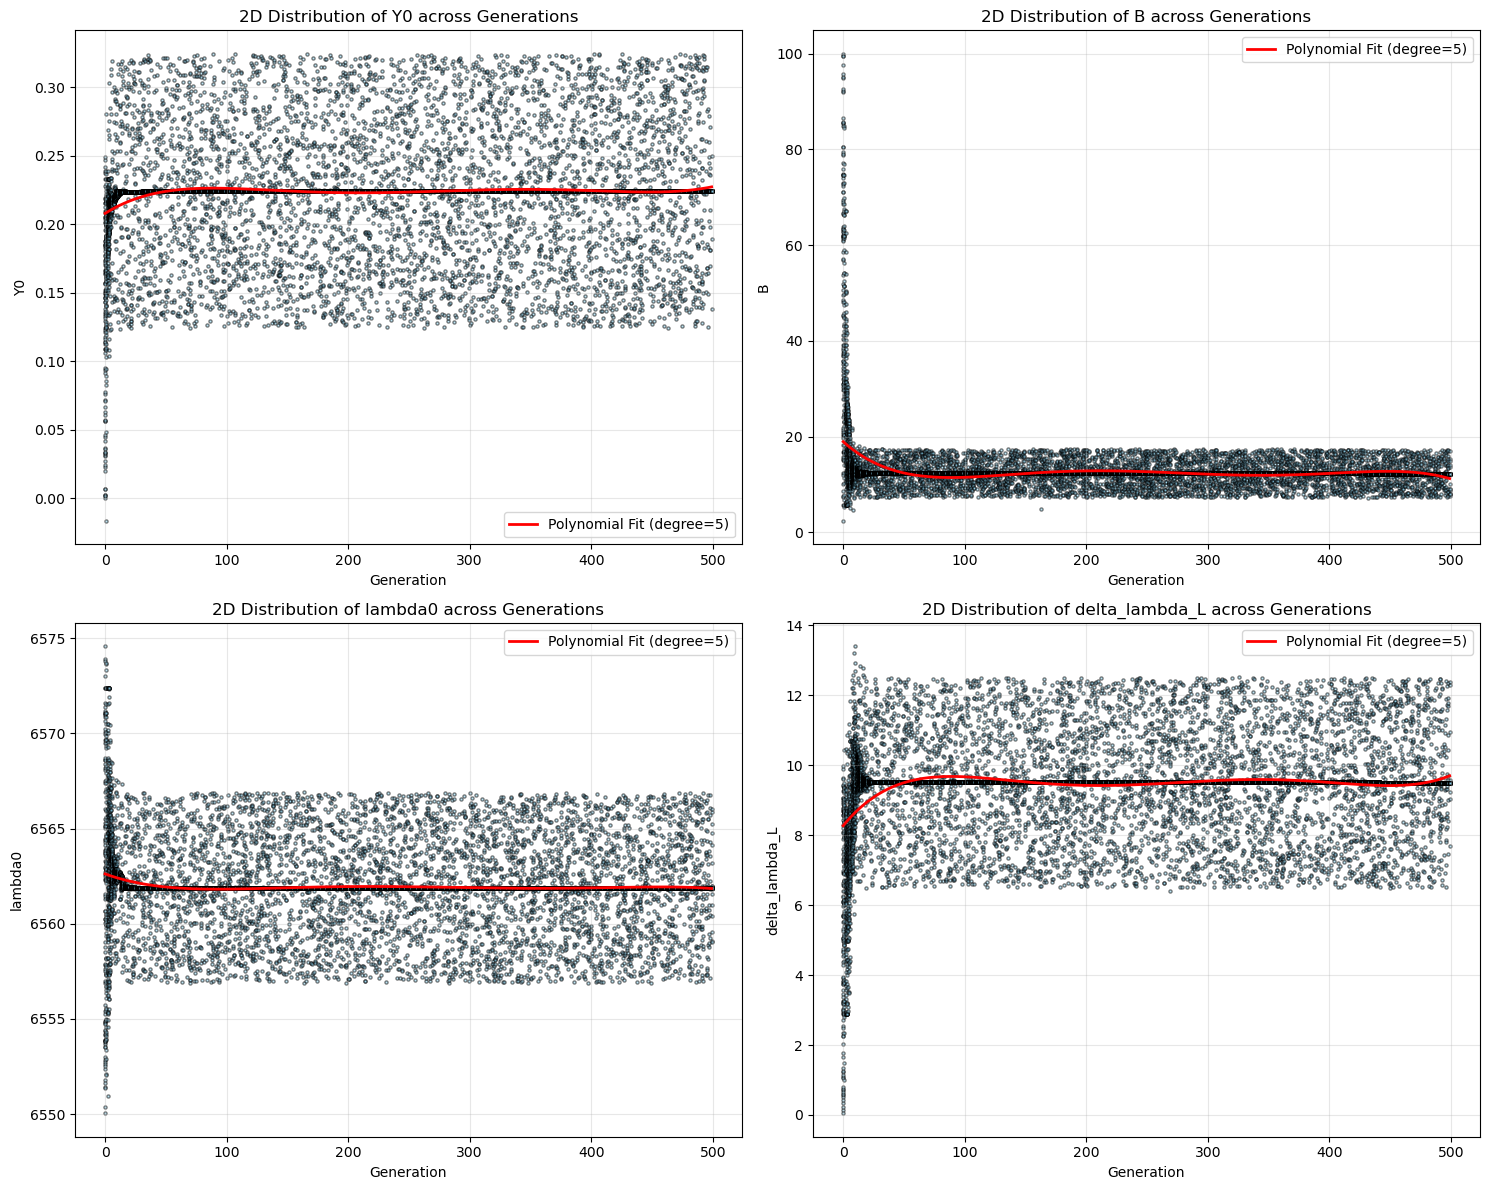

In [2]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

def plot_parameter_distribution_2d(df, degree=5):
    """
    绘制所有参数在不同代数上的二维分布图（散点图），并添加过拟合的多项式拟合曲线。
    
    :param df: DataFrame, 包含 Generation 和 参数值列（如 Y0, B, lambda0, delta_lambda_L）。
    :param degree: int, 多项式的度数，默认值为 5，可以根据需要调整。
    """
    fig = plt.figure(figsize=(15, 12))

    # 每个参数对应的名字
    param_names = ["Y0", "B", "lambda0", "delta_lambda_L"]

    # 迭代每个参数，绘制 2D 图
    for i, param_name in enumerate(param_names):
        ax = fig.add_subplot(2, 2, i + 1)

        # 收集每代该参数的值
        param_values = df[param_name]
        generations = df['Generation']

        # 每个代数的参数值
        x = generations  # Generation (代数)
        y = param_values  # Parameter values (参数值)

        # 将代数 (Generation) 转换为二维数组，以适应 scikit-learn 的输入格式
        x_reshape = np.array(x).reshape(-1, 1)
        y = np.array(y)

        # 使用多项式特征转换
        poly = PolynomialFeatures(degree)
        x_poly = poly.fit_transform(x_reshape)

        # 使用线性回归拟合多项式数据
        model = LinearRegression()
        model.fit(x_poly, y)

        # 获取拟合的结果
        y_pred = model.predict(x_poly)

        # 绘制散点图
        ax.scatter(x, y, color='skyblue', edgecolor='black', alpha=0.5, s=5)
        ax.plot(x, y_pred, color='red', linewidth=2, label=f"Polynomial Fit (degree={degree})")  # 绘制拟合的多项式曲线

        ax.set_xlabel('Generation')
        ax.set_ylabel(param_name)
        ax.set_title(f"2D Distribution of {param_name} across Generations")
        ax.grid(alpha=0.3)
        ax.legend()

    plt.tight_layout()
    plt.show()

# 调用函数绘制图表
plot_parameter_distribution_2d(df, degree=5)


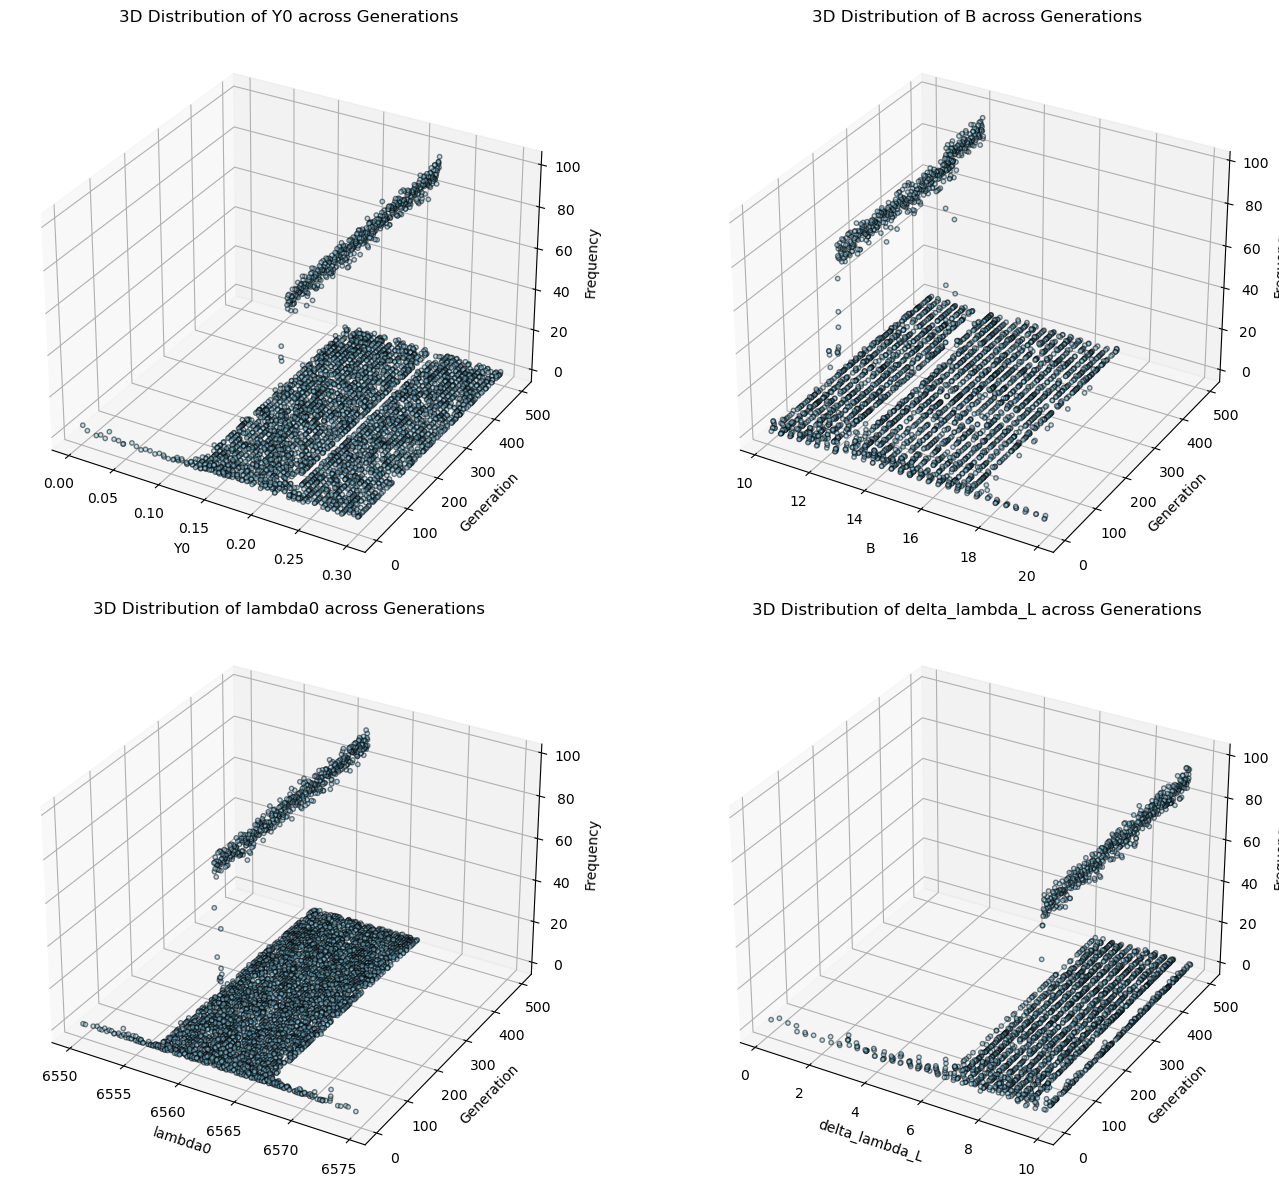

In [7]:
# 创建一个图形窗口
fig = plt.figure(figsize=(15, 12))

# 参数列表
param_names = ["Y0", "B", "lambda0", "delta_lambda_L"]

# 定义区间范围和分割数（每个参数分成100份）
param_bins = {
    "Y0": (0, 0.3, 60),  # Y0: 从 0 到 0.3，分成 60 份
    "B": (10, 20, 30),  # B: 从 10 到 20，分成 50 份
    "lambda0": (6500, 6600, 450),  # lambda0: 从 6500 到 6600，分成 450 份
    "delta_lambda_L": (0, 10, 32)  # delta_lambda_L: 从 0 到 10，分成 32 份
}

# 迭代所有参数，绘制3D图
for i, param_name in enumerate(param_names):
    ax = fig.add_subplot(2, 2, i + 1, projection='3d')

    # 获取每代每个个体的参数值
    param_values = df[param_name]
    generations = df['Generation']

    # 用来存储 X, Y, Z 轴的值
    x = []  # 存储区间的中间值
    y = []  # 存储代数
    z = []  # 存储区间内的频率

    # 获取每个参数的区间范围和分份数
    start, end, num_bins = param_bins[param_name]
    
    # 计算区间的宽度
    bin_width = (end - start) / num_bins
    bins = [start + i * bin_width for i in range(num_bins + 1)]  # 计算区间边界
    
    # 对每代数据进行遍历
    for gen in df['Generation'].unique():
        # 获取当前代的所有参数值
        gen_values = df[df['Generation'] == gen][param_name]

        # 使用pd.cut将参数值按区间划分
        bin_indices = pd.cut(gen_values, bins=bins, right=False)  # 不包含右边界

        # 计算每个区间的频率
        bin_counts = bin_indices.value_counts()

        # 对每个区间，将其中值作为 x 轴坐标，频率作为 z 轴坐标
        for bin_range, count in bin_counts.items():
            if count > 0:  # 只显示频率大于 0 的区间
                # 获取区间的中间值
                bin_center = (bin_range.left + bin_range.right) / 2
                x.append(bin_center)  # 将区间的中间值作为 X 坐标
                y.append(gen)  # 当前代作为 Y 坐标
                z.append(count)  # 该区间的频率作为 Z 坐标

    # 绘制3D散点图
    ax.scatter(x, y, z, color='skyblue', edgecolor='black', alpha=0.5, s=10)

    # 设置坐标轴标签
    ax.set_xlabel(param_name)
    ax.set_ylabel('Generation')
    ax.set_zlabel('Frequency')

    # 设置标题
    ax.set_title(f"3D Distribution of {param_name} across Generations")

# 调整布局，防止重叠
plt.tight_layout()

# 显示图表
plt.show()


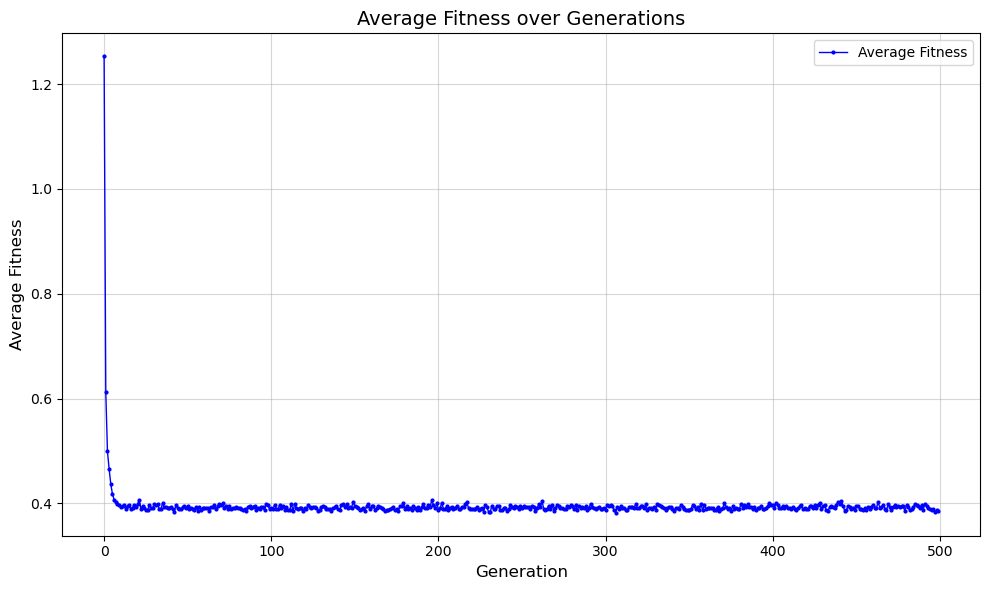

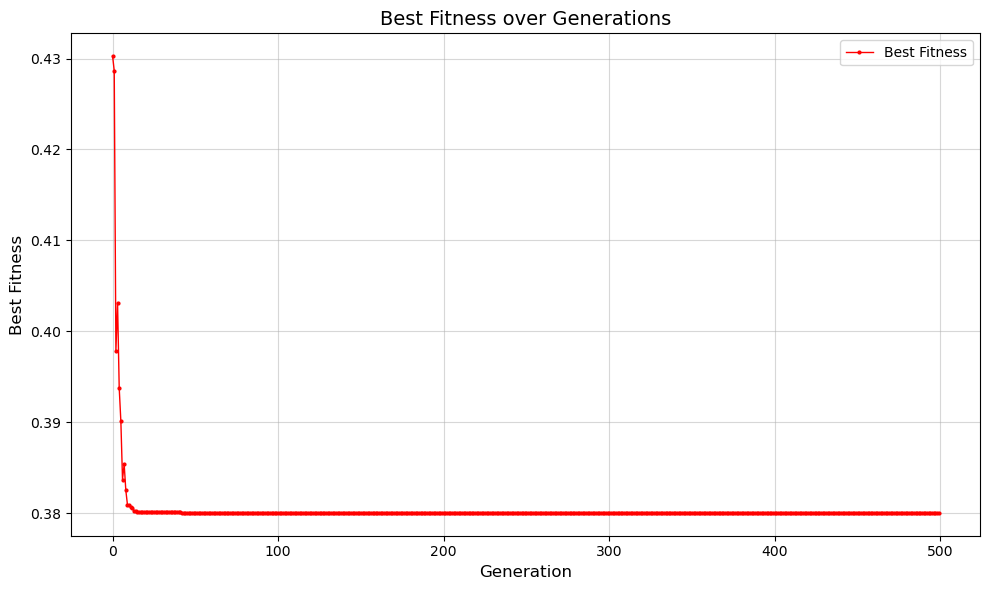

In [3]:
# 计算每代的平均适应度
avg_fitness = df.groupby('Generation')['Fitness'].mean()

# 绘制平均适应度变化曲线，调整点的大小

plt.figure(figsize=(10, 6))
plt.plot(avg_fitness.index, avg_fitness.values, marker='.', markersize=4, linewidth=1, label='Average Fitness', color='blue')
plt.xlabel('Generation', fontsize=12)
plt.ylabel('Average Fitness', fontsize=12)
plt.title('Average Fitness over Generations', fontsize=14)
plt.grid(alpha=0.5)  # 让网格线更淡
plt.legend(fontsize=10)
plt.tight_layout()  # 自动调整边距
plt.show()


plt.figure(figsize=(10, 6))
best_fitness = df.groupby('Generation')['Fitness'].min()
plt.plot(best_fitness.index, best_fitness.values, marker='.', markersize=4, linewidth=1, label='Best Fitness', color='r')
plt.xlabel('Generation', fontsize=12)
plt.ylabel('Best Fitness', fontsize=12)
plt.title('Best Fitness over Generations', fontsize=14)
plt.grid(alpha=0.5)  # 让网格线更淡
plt.legend(fontsize=10)
plt.tight_layout()  # 自动调整边距
plt.show()



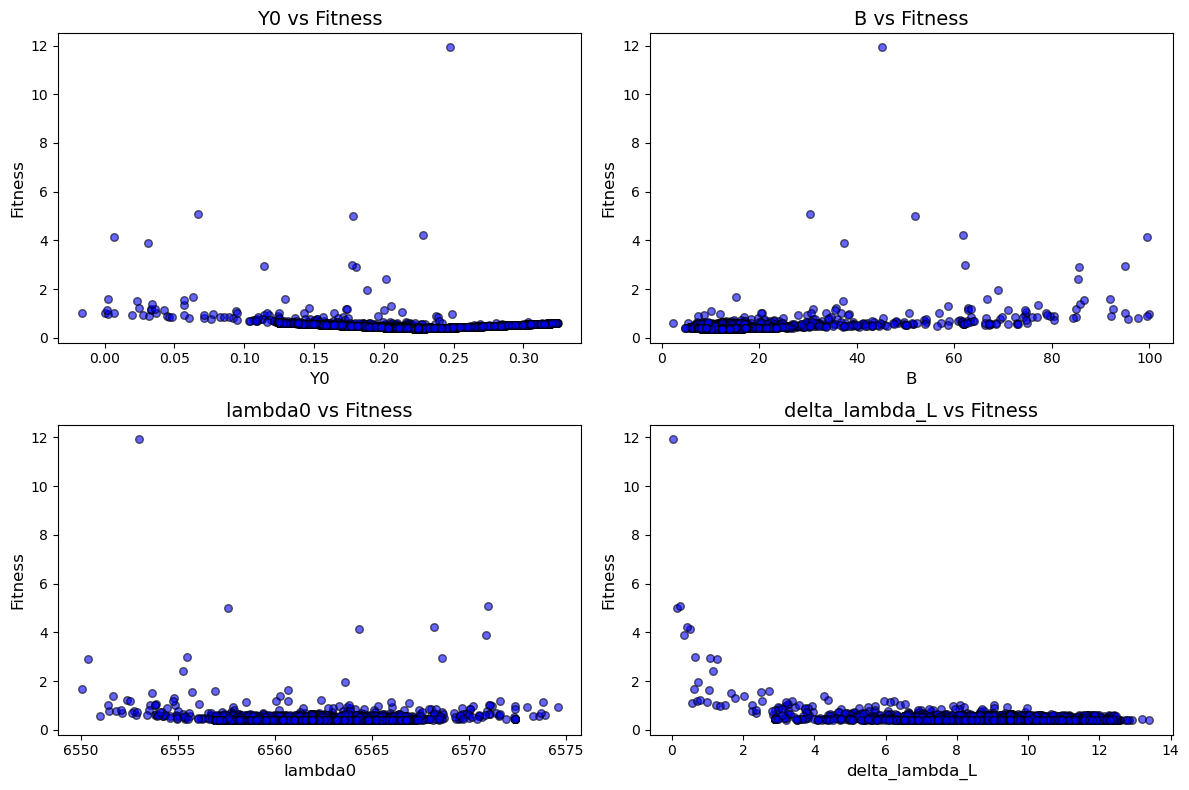

In [4]:
import matplotlib.pyplot as plt

# 绘制参数与适应度的散点图
plt.figure(figsize=(12, 8))

for i, param in enumerate(['Y0', 'B', 'lambda0', 'delta_lambda_L'], start=1):
    plt.subplot(2, 2, i)
    # 控制点的大小，通过 s 参数调整
    plt.scatter(df[param], df['Fitness'], alpha=0.6, s=30, c='b', edgecolors='k')  # s=30：点的大小，c='b'：点的颜色，edgecolors='k'：点的边框颜色
    plt.xlabel(param, fontsize=12)
    plt.ylabel('Fitness', fontsize=12)
    plt.title(f'{param} vs Fitness', fontsize=14)

# 调整图形布局，避免重叠
plt.tight_layout()
plt.show()


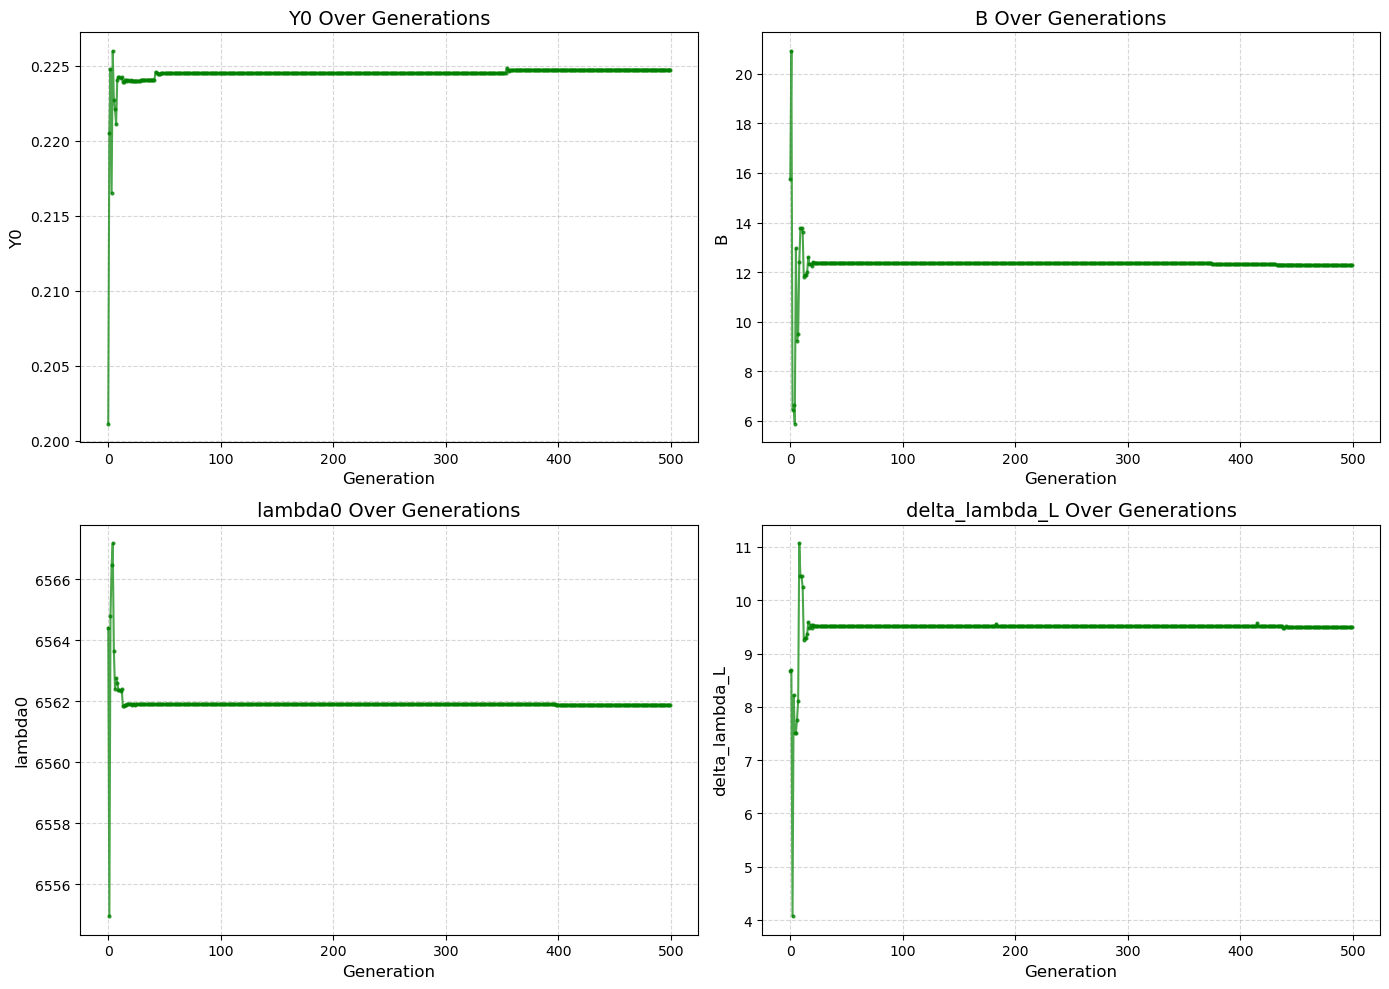

In [5]:
import matplotlib.pyplot as plt

# 获取每代的最优个体
best_individuals = df.loc[df.groupby('Generation')['Fitness'].idxmin()]

# 设置参数
params = ['Y0', 'B', 'lambda0', 'delta_lambda_L']

# 设置画布大小
plt.figure(figsize=(14, 10))

# 循环绘制每个参数的变化趋势
for i, param in enumerate(params, start=1):
    plt.subplot(2, 2, i)
    
    # 绘制曲线，使用平滑的线型和不同的颜色
    plt.plot(best_individuals['Generation'], best_individuals[param], marker='.', 
             color='g', linestyle='-', markersize=4, alpha=0.7, label=f'{param}')
    
    # 设置每个子图的标签和标题
    plt.xlabel('Generation', fontsize=12)
    plt.ylabel(param, fontsize=12)
    plt.title(f'{param} Over Generations', fontsize=14)
    
    # 添加网格
    plt.grid(True, linestyle='--', alpha=0.5)
    
    # 让坐标轴的刻度更加清晰
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)

# 调整子图间距
plt.tight_layout()

# 显示图形
plt.show()


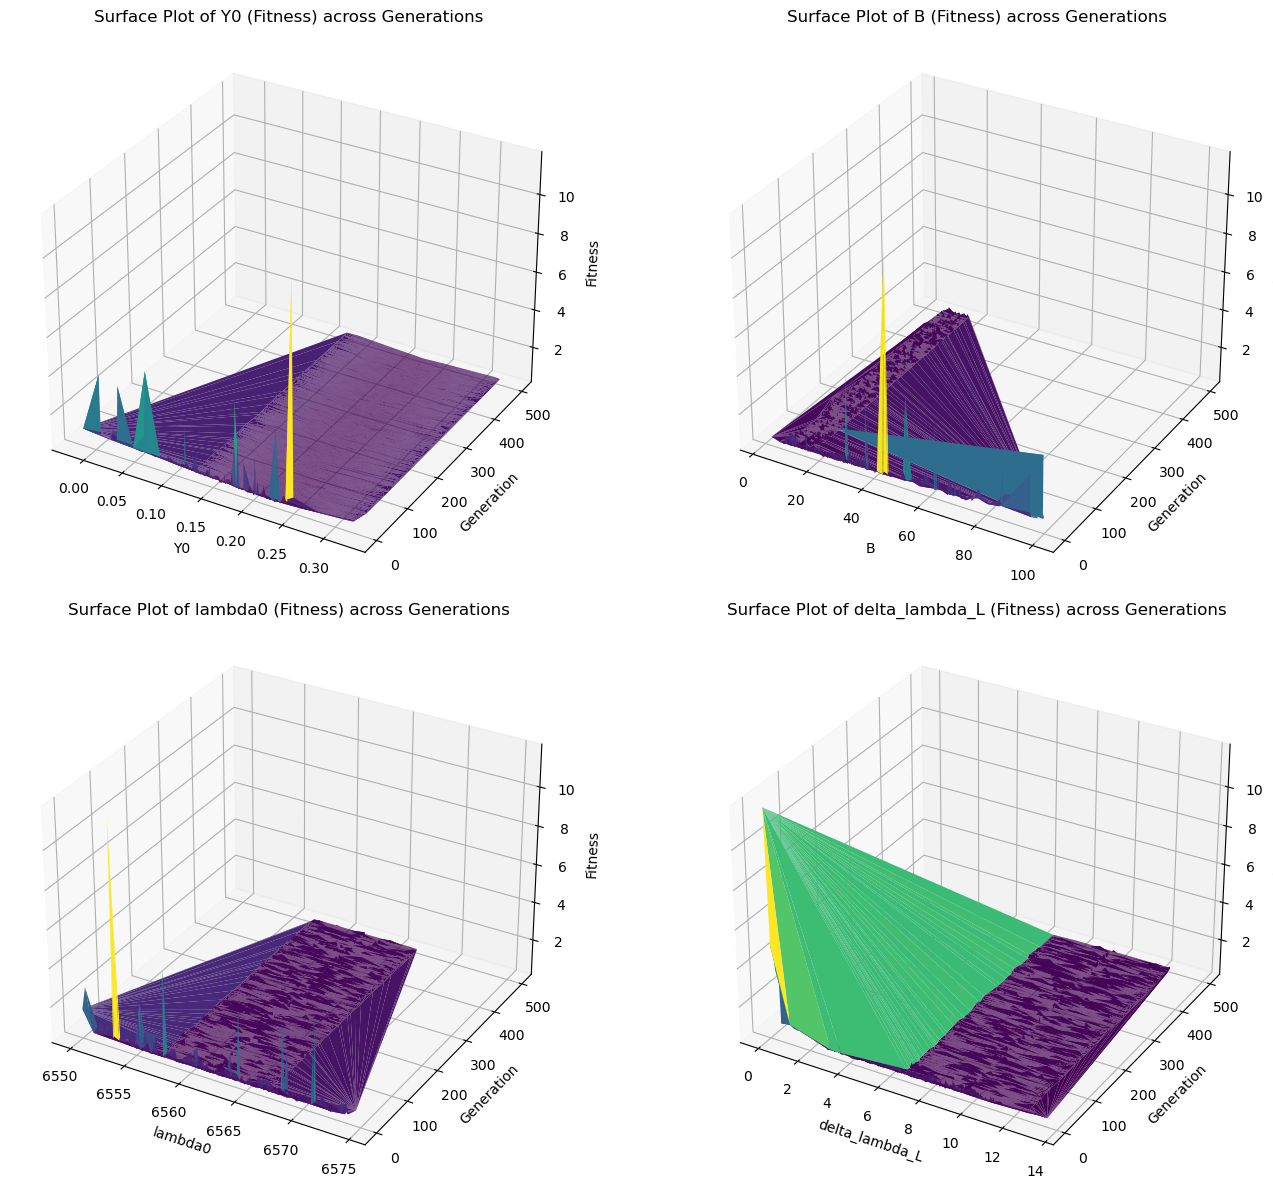

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# 读取CSV文件
df = pd.read_csv(r'C:\Users\QianBoda\Desktop\Project_Numerique\N2_C\N2_C\genetic_algorithm_data.csv')

# 创建一个图形窗口
fig = plt.figure(figsize=(15, 12))

# 参数列表
param_names = ["Y0", "B", "lambda0", "delta_lambda_L"]

# 迭代所有参数，绘制3D图
for i, param_name in enumerate(param_names):
    ax = fig.add_subplot(2, 2, i + 1, projection='3d')

    # 获取每代每个个体的参数值和适应度
    x = []
    y = []
    z = []

    # 遍历每代数据
    for gen in df['Generation'].unique():
        gen_data = df[df['Generation'] == gen]
        for _, row in gen_data.iterrows():
            x.append(row[param_name])  # 参数值
            y.append(gen)  # 代数
            z.append(row['Fitness'])  # 适应度值

    # 将数据转换为 numpy 数组，方便绘制
    x = np.array(x)
    y = np.array(y)
    z = np.array(z)

    # 使用 trisurf 绘制表面图
    ax.plot_trisurf(x, y, z, cmap='viridis', edgecolor='none')

    # 设置坐标轴标签
    ax.set_xlabel(param_name)
    ax.set_ylabel('Generation')
    ax.set_zlabel('Fitness')

    # 设置标题
    ax.set_title(f"Surface Plot of {param_name} (Fitness) across Generations")

# 调整布局，防止重叠
plt.tight_layout()

# 显示图表
plt.show()

